In [ ]:
# ---- Cell 1: imports, seed, versions ----
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scipy.stats as stats
import sklearn
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("statsmodels :", statsmodels.__version__)
print("scipy       :", scipy.__version__)

Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
statsmodels : 0.15.0
scipy       : 1.16.3


Role: Data analyst at an automobile consultancy.
Question: Which car characteristics explain fuel efficiency, and can we forecast mpg
for a car design before it is built?
User/decision: Product planners who want to estimate the mpg impact of design choices.
X: displacement, horsepower, weight, acceleration, model_year
y: mpg (miles per gallon)
Success metric: Test RMSE (in mpg) and test R², beating a "predict the mean" baseline.

In [ ]:
# ---- Cell 2: load ----
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(URL)

print("Rows, columns:", df.shape)
df.head(10)

Rows, columns: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
5,15.0,8,429.0,198.0,4341,10.0,70,usa,ford galaxie 500
6,14.0,8,454.0,220.0,4354,9.0,70,usa,chevrolet impala
7,14.0,8,440.0,215.0,4312,8.5,70,usa,plymouth fury iii
8,14.0,8,455.0,225.0,4425,10.0,70,usa,pontiac catalina
9,15.0,8,390.0,190.0,3850,8.5,70,usa,amc ambassador dpl


In [ ]:
# ---- Cell 3: structure, summary, quality checks ----
print(df.dtypes, "\n")
display(df.describe().T)          # shows range and units of every numeric column
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin           object
name             object
dtype: object 



,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0



Missing values per column:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Duplicate rows: 0


In [ ]:
# ---- Cell 4: define X and y, then clean ----
TARGET = "mpg"
FEATURES = ["displacement", "horsepower", "weight", "acceleration", "model_year"]

data = df[FEATURES + [TARGET]].copy()

# Check for impossible values (units must be positive)
assert (data[["displacement", "horsepower", "weight", "acceleration", "mpg"]] > 0).all().all() or data.isna().any().any()

n_before = len(data)
data = data.dropna().drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before}, after cleaning: {len(data)} "
      f"(removed {n_before - len(data)} rows, {100*(n_before-len(data))/n_before:.1f}%)")

Rows before: 398, after cleaning: 392 (removed 6 rows, 1.5%)


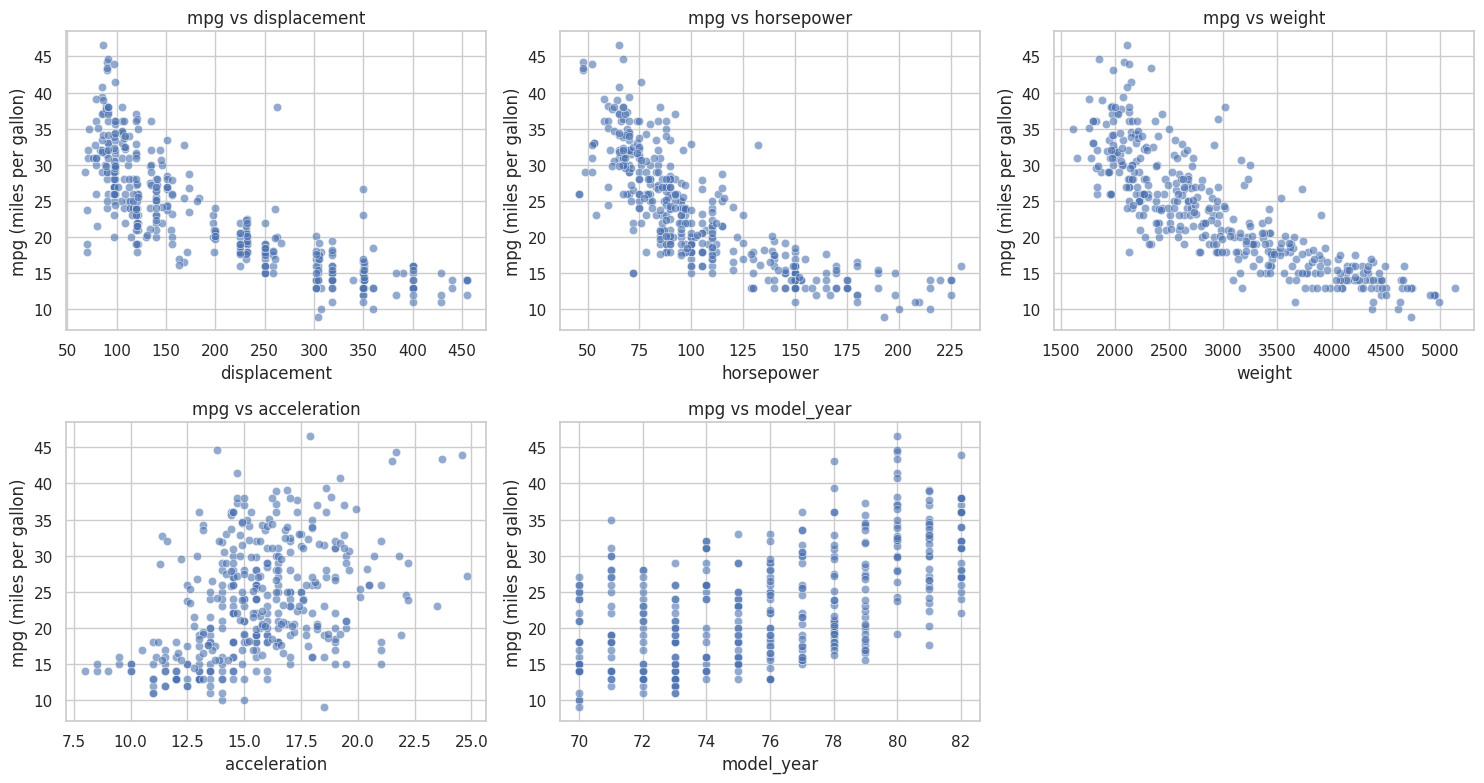

In [ ]:
# ---- Cell 5: scatter plots of target vs each feature ----
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.scatterplot(data=data, x=col, y=TARGET, ax=ax, alpha=0.6)
    ax.set_title(f"mpg vs {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("mpg (miles per gallon)")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

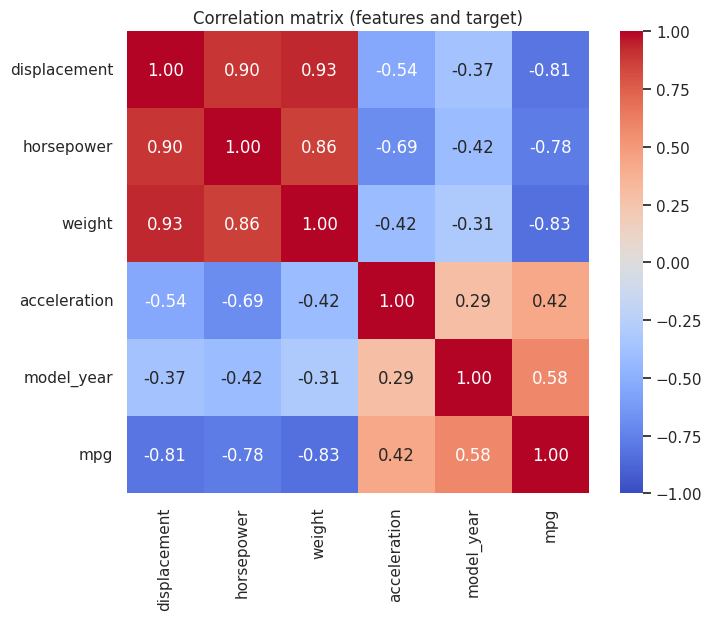

Correlation of each feature with mpg:
weight         -0.832244
displacement   -0.805127
horsepower     -0.778427
model_year      0.580541
acceleration    0.423329
Name: mpg, dtype: float64

Feature pairs with |r| > 0.8 (possible multicollinearity):
  displacement and horsepower: r = 0.90
  displacement and weight: r = 0.93
  horsepower and weight: r = 0.86


In [ ]:
# ---- Cell 6: correlation heatmap ----
corr = data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (features and target)")
plt.show()

print("Correlation of each feature with mpg:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False))

# Pairs of features that are strongly correlated with each other
feat_corr = data[FEATURES].corr()
pairs = [(a, b, feat_corr.loc[a, b]) for i, a in enumerate(FEATURES)
         for b in FEATURES[i+1:] if abs(feat_corr.loc[a, b]) > 0.8]
print("\nFeature pairs with |r| > 0.8 (possible multicollinearity):")
for a, b, r in pairs:
    print(f"  {a} and {b}: r = {r:.2f}")

In [ ]:
# ---- Cell 7: choose the small sample ----
sample = data.sample(6, random_state=SEED)[["weight", "horsepower", "mpg"]].copy()
sample["weight"] = sample["weight"] / 1000        # now in 1000 lbs
sample = sample.reset_index(drop=True)
sample.index = sample.index + 1
sample.index.name = "obs"
print("Sample (x1 = weight in 1000 lbs, x2 = horsepower, y = mpg)")
display(sample)

Sample (x1 = weight in 1000 lbs, x2 = horsepower, y = mpg)


,weight,horsepower,mpg
obs,,,
1,2.189,69.0,26.0
2,2.795,115.0,21.6
3,1.800,60.0,36.1
4,1.955,70.0,26.0
5,2.790,86.0,27.0
6,2.155,75.0,28.0


In [ ]:
# ---- Cell 8: design matrix, XtX, Xty ----
x1 = sample["weight"].values
x2 = sample["horsepower"].values
y  = sample["mpg"].values
n  = len(y)

X = np.column_stack([np.ones(n), x1, x2])     # column of ones, x1, x2
print("Design matrix X (columns: 1, x1, x2):\n", np.round(X, 3))
print("\nTarget vector y:\n", y)

XtX = X.T @ X
Xty = X.T @ y
print("\nX^T X =\n", np.round(XtX, 4))
print("\nX^T y =\n", np.round(Xty, 4))

# Also show the individual sums so you can verify by calculator
print("\nSums for hand-checking:")
print(f"n = {n}")
print(f"Σx1 = {x1.sum():.4f}, Σx2 = {x2.sum():.4f}, Σy = {y.sum():.4f}")
print(f"Σx1² = {(x1**2).sum():.4f}, Σx2² = {(x2**2).sum():.4f}, Σx1x2 = {(x1*x2).sum():.4f}")
print(f"Σx1y = {(x1*y).sum():.4f}, Σx2y = {(x2*y).sum():.4f}")

Design matrix X (columns: 1, x1, x2):
 [[  1.      2.189  69.   ]
 [  1.      2.795 115.   ]
 [  1.      1.8    60.   ]
 [  1.      1.955  70.   ]
 [  1.      2.79   86.   ]
 [  1.      2.155  75.   ]]

Target vector y:
 [26.  21.6 36.1 26.  27.  28. ]

X^T X =
 [[6.000000e+00 1.368400e+01 4.750000e+02]
 [1.368400e+01 3.209390e+01 1.118881e+03]
 [4.750000e+02 1.118881e+03 3.950700e+04]]

X^T y =
 [  164.7     368.766 12686.   ]

Sums for hand-checking:
n = 6
Σx1 = 13.6840, Σx2 = 475.0000, Σy = 164.7000
Σx1² = 32.0939, Σx2² = 39507.0000, Σx1x2 = 1118.8810
Σx1y = 368.7660, Σx2y = 12686.0000


In [ ]:
# ---- Cell 9: solve (XtX) b = Xty by Gauss-Jordan elimination, step by step ----
def gauss_jordan_steps(A, b):
    M = np.hstack([A.astype(float), b.reshape(-1, 1)])
    m = len(b)
    print("Augmented matrix [XtX | Xty]:\n", np.round(M, 4))
    for i in range(m):
        pivot = M[i, i]
        M[i] = M[i] / pivot
        print(f"\nR{i+1} <- R{i+1} / {pivot:.4f}\n", np.round(M, 4))
        for j in range(m):
            if j != i:
                factor = M[j, i]
                M[j] = M[j] - factor * M[i]
                print(f"R{j+1} <- R{j+1} - ({factor:.4f}) x R{i+1}")
        print(np.round(M, 4))
    return M[:, -1]

b_manual = gauss_jordan_steps(XtX, Xty)
b0, b1, b2 = b_manual
print(f"\nSolved: b0 = {b0:.4f}, b1 = {b1:.4f}, b2 = {b2:.4f}")

# Cross-check with the matrix-inverse method
b_inv = np.linalg.inv(XtX) @ Xty
print("Matrix-inverse method:", np.round(b_inv, 4))
print("det(XtX) =", round(np.linalg.det(XtX), 4), "(must be non-zero for a unique solution)")

Augmented matrix [XtX | Xty]:
 [[6.000000e+00 1.368400e+01 4.750000e+02 1.647000e+02]
 [1.368400e+01 3.209390e+01 1.118881e+03 3.687660e+02]
 [4.750000e+02 1.118881e+03 3.950700e+04 1.268600e+04]]

R1 <- R1 / 6.0000
 [[1.000000e+00 2.280700e+00 7.916670e+01 2.745000e+01]
 [1.368400e+01 3.209390e+01 1.118881e+03 3.687660e+02]
 [4.750000e+02 1.118881e+03 3.950700e+04 1.268600e+04]]
R2 <- R2 - (13.6840) x R1
R3 <- R3 - (475.0000) x R1
[[ 1.0000000e+00  2.2807000e+00  7.9166700e+01  2.7450000e+01]
 [ 0.0000000e+00  8.8530000e-01  3.5564300e+01 -6.8598000e+00]
 [ 0.0000000e+00  3.5564300e+01  1.9028333e+03 -3.5275000e+02]]

R2 <- R2 / 0.8853
 [[ 1.0000000e+00  2.2807000e+00  7.9166700e+01  2.7450000e+01]
 [ 0.0000000e+00  1.0000000e+00  4.0174200e+01 -7.7490000e+00]
 [ 0.0000000e+00  3.5564300e+01  1.9028333e+03 -3.5275000e+02]]
R1 <- R1 - (2.2807) x R2
R3 <- R3 - (35.5643) x R2
[[  1.       0.     -12.4573  45.1228]
 [  0.       1.      40.1742  -7.749 ]
 [  0.       0.     474.0651 -77.16

In [ ]:
# ---- Cell 10: fitted equation, one prediction, one residual ----
print(f"Fitted equation (sample): mpg = {b0:.3f} + ({b1:.3f}) x weight_1000lb + ({b2:.3f}) x horsepower")

k = 0                                    # first observation
y_hat = b0 + b1 * x1[k] + b2 * x2[k]
print(f"\nObservation {k+1}: weight={x1[k]:.3f}, hp={x2[k]:.0f}")
print(f"Predicted mpg = {y_hat:.3f}")
print(f"Actual mpg    = {y[k]:.3f}")
print(f"Residual (actual - predicted) = {y[k] - y_hat:.3f}")

Fitted equation (sample): mpg = 43.095 + (-1.210) x weight_1000lb + (-0.163) x horsepower

Observation 1: weight=2.189, hp=69
Predicted mpg = 29.216
Actual mpg    = 26.000
Residual (actual - predicted) = -3.216


In [ ]:
# ---- Cell 11: train/test split (80:20) ----
X_all = data[FEATURES]
y_all = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=SEED)

print("Training observations:", len(X_train))
print("Testing observations :", len(X_test))

Training observations: 313
Testing observations : 79


In [ ]:
# ---- Cell 12: baseline 0: always predict the training mean ----
def reg_metrics(y_true, y_pred, p):
    """p = number of features used by the model."""
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adj R2": adj}

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
m_dummy = reg_metrics(y_test, dummy.predict(X_test), p=0)
print("Mean-prediction baseline on test set:", {k: round(v, 3) for k, v in m_dummy.items()})

Mean-prediction baseline on test set: {'MAE': 5.881, 'MSE': 51.62, 'RMSE': np.float64(7.185), 'R2': -0.011, 'Adj R2': -0.011}


In [ ]:
# ---- Cell 13: single-feature model (most correlated feature, chosen on TRAIN only) ----
train_corr = pd.concat([X_train, y_train], axis=1).corr()[TARGET].drop(TARGET)
best_feat = train_corr.abs().idxmax()
print("Most correlated feature with mpg (train):", best_feat, f"(r = {train_corr[best_feat]:.3f})")

lr1 = LinearRegression().fit(X_train[[best_feat]], y_train)
print(f"Intercept: {lr1.intercept_:.4f}")
print(f"Coefficient for {best_feat}: {lr1.coef_[0]:.6f}")

pred1 = lr1.predict(X_test[[best_feat]])
m_single = reg_metrics(y_test, pred1, p=1)
print("Single-feature test metrics:", {k: round(v, 3) for k, v in m_single.items()})

Most correlated feature with mpg (train): weight (r = -0.836)
Intercept: 47.2005
Coefficient for weight: -0.007904
Single-feature test metrics: {'MAE': 3.464, 'MSE': 17.693, 'RMSE': np.float64(4.206), 'R2': 0.653, 'Adj R2': 0.649}


In [ ]:
# ---- Cell 14: multiple linear regression (train only) ----
lr_multi = LinearRegression().fit(X_train, y_train)

print(f"Intercept (b0): {lr_multi.intercept_:.4f}")
coef_table = pd.DataFrame({"Feature": FEATURES, "Coefficient": lr_multi.coef_})
display(coef_table)

pred_multi = lr_multi.predict(X_test)
m_multi = reg_metrics(y_test, pred_multi, p=len(FEATURES))
print("Multiple-regression test metrics:", {k: round(v, 3) for k, v in m_multi.items()})

Intercept (b0): -15.3516


,Feature,Coefficient
0,displacement,-0.000727
1,horsepower,-0.001974
2,weight,-0.006582
3,acceleration,0.062448
4,model_year,0.760870


Multiple-regression test metrics: {'MAE': 2.513, 'MSE': 10.579, 'RMSE': np.float64(3.252), 'R2': 0.793, 'Adj R2': 0.779}


In [ ]:
# ---- Cell 15: scaling (fit on TRAIN only) to compare coefficient sizes ----
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

lr_scaled = LinearRegression().fit(X_train_s, y_train)
std_coef = pd.DataFrame({
    "Feature": FEATURES,
    "Raw coef (per original unit)": lr_multi.coef_,
    "Standardised coef (per 1 SD)": lr_scaled.coef_
}).sort_values("Standardised coef (per 1 SD)", key=abs, ascending=False)
display(std_coef)

# Scaling does not change the predictions of OLS, only the meaning/size of coefficients
print("Same test predictions after scaling?",
      np.allclose(lr_scaled.predict(X_test_s), pred_multi))

,Feature,Raw coef (per original unit),Standardised coef (per 1 SD)
2,weight,-0.006582,-5.527638
4,model_year,0.760870,2.757645
3,acceleration,0.062448,0.175688
1,horsepower,-0.001974,-0.075446
0,displacement,-0.000727,-0.075355


Same test predictions after scaling? True


In [ ]:
# ---- Cell 16: library check of the hand calculation (same 6 rows, same 2 features) ----
lr_check = LinearRegression().fit(sample[["weight", "horsepower"]], sample["mpg"])
print("Hand calculation  :", np.round([b0, b1, b2], 6))
print("Library (sklearn) :", np.round([lr_check.intercept_, *lr_check.coef_], 6))
print("Match?", np.allclose([b0, b1, b2], [lr_check.intercept_, *lr_check.coef_]))

Hand calculation  : [43.095157 -1.209856 -0.162769]
Library (sklearn) : [43.095157 -1.209856 -0.162769]
Match? True


In [ ]:
# ---- Cell 17: print the full-data equation ----
terms = " ".join([f"{c:+.5f}*{f}" for f, c in zip(FEATURES, lr_multi.coef_)])
print(f"mpg = {lr_multi.intercept_:.4f} {terms}")

mpg = -15.3516 -0.00073*displacement -0.00197*horsepower -0.00658*weight +0.06245*acceleration +0.76087*model_year


In [ ]:
# ---- Cell 18: actual vs predicted (TEST set only) ----
comparison = pd.DataFrame({
    "Actual mpg": y_test.values,
    "Predicted mpg": pred_multi,
}, index=y_test.index)
comparison["Error (actual - predicted)"] = comparison["Actual mpg"] - comparison["Predicted mpg"]
display(comparison.round(2).sample(12, random_state=SEED))

,Actual mpg,Predicted mpg,Error (actual - predicted)
155,15.0,12.82,2.18
78,26.0,25.94,0.06
345,34.1,34.01,0.09
255,19.4,23.60,-4.20
294,27.4,27.87,-0.47
101,26.0,28.51,-2.51
9,15.0,12.44,2.56
45,22.0,23.76,-1.76
387,27.0,29.38,-2.38
287,16.9,16.43,0.47


In [ ]:
# ---- Cell 19: comparison table (TEST set) ----
results = pd.DataFrame({
    "Mean baseline": m_dummy,
    f"Single feature ({best_feat})": m_single,
    "Multiple (5 features)": m_multi,
}).T
display(results.round(3))

,MAE,MSE,RMSE,R2,Adj R2
Mean baseline,5.881,51.620,7.185,-0.011,-0.011
Single feature (weight),3.464,17.693,4.206,0.653,0.649
Multiple (5 features),2.513,10.579,3.252,0.793,0.779


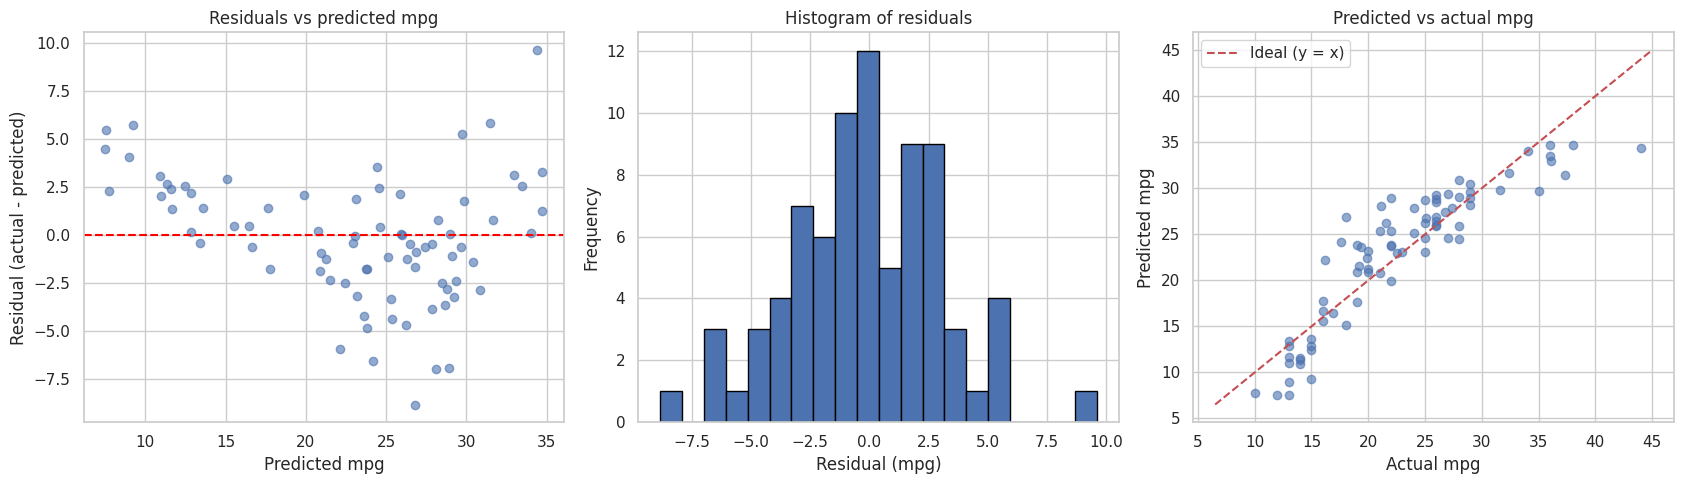

In [ ]:
# ---- Cell 20: residual plots (TEST set) ----
resid = y_test.values - pred_multi

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) residuals vs predicted
axes[0].scatter(pred_multi, resid, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs predicted mpg")
axes[0].set_xlabel("Predicted mpg")
axes[0].set_ylabel("Residual (actual - predicted)")

# (b) histogram of residuals
axes[1].hist(resid, bins=20, edgecolor="black")
axes[1].set_title("Histogram of residuals")
axes[1].set_xlabel("Residual (mpg)")
axes[1].set_ylabel("Frequency")

# (c) predicted vs actual with 45-degree line
lims = [min(y_test.min(), pred_multi.min()) - 1, max(y_test.max(), pred_multi.max()) + 1]
axes[2].scatter(y_test, pred_multi, alpha=0.6)
axes[2].plot(lims, lims, "r--", label="Ideal (y = x)")
axes[2].set_title("Predicted vs actual mpg")
axes[2].set_xlabel("Actual mpg")
axes[2].set_ylabel("Predicted mpg")
axes[2].legend()

plt.tight_layout()
plt.show()

Shapiro-Wilk p-value = 0.8734  (p < 0.05 suggests residuals are not perfectly normal)
Breusch-Pagan p-value = 0.0784  (p < 0.05 suggests non-constant variance)


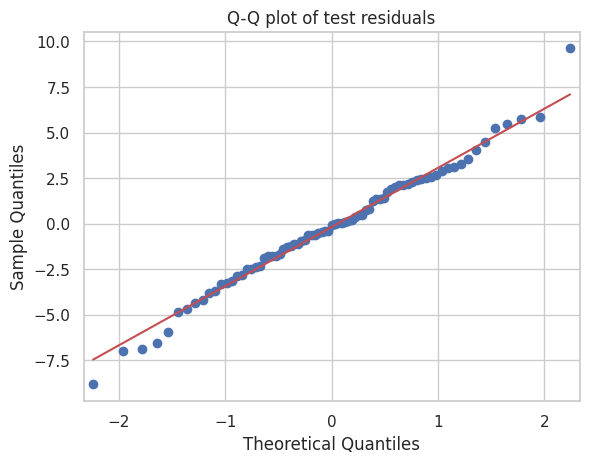

In [ ]:
# ---- Cell 21: numeric assumption checks ----
# Normality of residuals
sw_stat, sw_p = stats.shapiro(resid)
print(f"Shapiro-Wilk p-value = {sw_p:.4f}  (p < 0.05 suggests residuals are not perfectly normal)")

# Constant variance (Breusch-Pagan)
bp = het_breuschpagan(resid, sm.add_constant(X_test))
print(f"Breusch-Pagan p-value = {bp[1]:.4f}  (p < 0.05 suggests non-constant variance)")

# Q-Q plot
sm.qqplot(resid, line="s")
plt.title("Q-Q plot of test residuals")
plt.show()

In [ ]:
# ---- Cell 22: VIF (computed on TRAIN features) ----
Xc = sm.add_constant(X_train)
vif = pd.DataFrame({
    "Feature": Xc.columns,
    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]
})
display(vif[vif["Feature"] != "const"].sort_values("VIF", ascending=False).round(2))

,Feature,VIF
1,displacement,10.11
3,weight,9.94
2,horsepower,9.34
4,acceleration,2.68
5,model_year,1.28


In [ ]:
# ---- Cell 23: what happens if we drop the most redundant feature? ----
worst = vif[vif["Feature"] != "const"].sort_values("VIF", ascending=False).iloc[0]["Feature"]
reduced = [f for f in FEATURES if f != worst]

lr_red = LinearRegression().fit(X_train[reduced], y_train)
m_red = reg_metrics(y_test, lr_red.predict(X_test[reduced]), p=len(reduced))

print("Dropped feature:", worst)
display(pd.DataFrame({"All 5 features": m_multi, f"Without {worst}": m_red}).T.round(3))

Dropped feature: displacement


,MAE,MSE,RMSE,R2,Adj R2
All 5 features,2.513,10.579,3.252,0.793,0.779
Without displacement,2.512,10.553,3.249,0.793,0.782


In [ ]:
# ---- Cell 24: predict one new car, inside the training range ----
print("Training ranges:")
display(X_train.agg(["min", "max"]).T)

new_car = pd.DataFrame([{
    "displacement": 150,    # cubic inches
    "horsepower": 100,      # hp
    "weight": 2800,         # lbs
    "acceleration": 15,     # seconds
    "model_year": 78
}])[FEATURES]

# Safety check: warn if extrapolating
for f in FEATURES:
    lo, hi = X_train[f].min(), X_train[f].max()
    if not (lo <= new_car.loc[0, f] <= hi):
        print(f"WARNING: {f} = {new_car.loc[0, f]} is outside the training range [{lo}, {hi}]")

pred_new = lr_multi.predict(new_car)[0]
print(f"\nPredicted fuel efficiency: {pred_new:.1f} mpg (typical error about ±{m_multi['RMSE']:.1f} mpg)")

Training ranges:


,min,max
displacement,70.0,455.0
horsepower,46.0,230.0
weight,1613.0,5140.0
acceleration,8.0,24.8
model_year,70.0,82.0



Predicted fuel efficiency: 26.2 mpg (typical error about ±3.3 mpg)
